In [1]:
!pip install segmentation_models_pytorch torchmetrics --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 106.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 81.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 90.3 MB/s eta 0:00:00


In [2]:
import os
import torch
import numpy as np 
import random 
import seaborn as sns
from torchvision import transforms
import matplotlib.pyplot as plt

plt.style.use('dark_background')

data = "/kaggle/input/cxr-dataset/"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LABEL_MAP = {'normal': 0, 'covid': 1, 'pneumonia': 2}
LABEL_NAMES = {v: k.capitalize() for k, v in LABEL_MAP.items()}

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed = 42
set_seed(seed)

In [3]:
from glob import glob
from PIL import Image
from collections import defaultdict, Counter
from sklearn.model_selection import StratifiedShuffleSplit

from torch.utils.data import Dataset, DataLoader, Subset

class MultiTaskXrayDataset(Dataset):
    def __init__(self, image_paths, mask_paths, infection_paths, labels, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.infection_paths = infection_paths
        self.labels = [LABEL_MAP[l] if isinstance(l, str) else l for l in labels]
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = np.array(Image.open(self.image_paths[idx]).convert("L"))
        mask = np.array(Image.open(self.mask_paths[idx]).convert("L"))
        infection_mask = np.array(Image.open(self.infection_paths[idx]).convert("L"))
        label = self.labels[idx]

        if self.transform:
            augmented = self.transform(
                image=image,
                masks=[mask, infection_mask]
            )
            image = augmented["image"]
            mask, infection_mask = augmented["masks"]

        # Convert to torch and build one-hot targets
        if not isinstance(mask, torch.Tensor):
            mask = torch.tensor(mask, dtype=torch.long)
            infection_mask = torch.tensor(infection_mask, dtype=torch.long)

        seg_targets = torch.zeros((3, mask.shape[0], mask.shape[1]), dtype=torch.float32)
        seg_targets[0] = ((mask == 0) & (infection_mask == 0)).float()
        seg_targets[1] = (mask > 0).float()
        seg_targets[2] = (infection_mask > 0).float()

        return image, label, seg_targets

def load_all_paths(root_dir):
    image_paths, mask_paths, infected_paths, labels = [], [], [], []

    for class_name in ['covid', 'normal', 'pneumonia']:
        img_dir = os.path.join(root_dir, class_name, class_name, 'images')
        mask_dir = os.path.join(root_dir, class_name, class_name, 'masks')
        inf_dir = os.path.join(root_dir, class_name, class_name, 'infection masks')

        images = sorted(glob(os.path.join(img_dir, '*.png')))
        masks = sorted(glob(os.path.join(mask_dir, '*.png')))
        infected = sorted(glob(os.path.join(inf_dir, '*.png')))

        assert len(images) == len(masks) == len(infected), f"Mismatch in {class_name} samples"

        label = [class_name] * len(images)

        image_paths.extend(images)
        mask_paths.extend(masks)
        infected_paths.extend(infected)
        labels.extend(label)

    return image_paths, mask_paths, infected_paths, labels

def create_dataloaders(root_dir, batch_size=8, val_ratio=0.2, seed=42, transform=None, val_transform=None):
    image_paths, lung_paths, lesion_paths, labels = load_all_paths(root_dir)
    
    sss = StratifiedShuffleSplit(n_splits=1, test_size=val_ratio, random_state=seed)
    train_idx, val_idx = next(sss.split(image_paths, labels))

    def select(arr, idx): return [arr[i] for i in idx]

    train_dataset = MultiTaskXrayDataset(
        select(image_paths, train_idx),
        select(lung_paths, train_idx),
        select(lesion_paths, train_idx),
        select(labels, train_idx),
        transform=transform,
    )

    val_dataset = MultiTaskXrayDataset(
        select(image_paths, val_idx),
        select(lung_paths, val_idx),
        select(lesion_paths, val_idx),
        select(labels, val_idx),
        transform=val_transform,
    )

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    return train_loader, val_loader

def get_class_weights(dataset, device="cpu"):
    labels = [dataset.labels[i] if hasattr(dataset, 'labels') else dataset[i]['label'] for i in range(len(dataset))]
    count = Counter(labels)

    counts = torch.tensor([count[c] for c in sorted(count.keys())], dtype=torch.float)

    weights = 1.0 / counts
    weights = weights / weights.sum()

    return weights.to(device)

In [4]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

batch_size = 16
resize = (256, 256)
val_ratio = 0.2

transform = A.Compose([
    A.Resize(height=resize[0], width=resize[1]),

    # Geometric
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, border_mode=0, p=0.3),
    A.Affine(
        scale=(0.98, 1.02),
        translate_percent=(0.02, 0.02),
        rotate=0,
        p=0.2
    ),

    # Appearance
    A.RandomBrightnessContrast(brightness_limit=0.05, contrast_limit=0.05, p=0.3),
    A.RandomGamma(gamma_limit=(90, 110), p=0.2),

    # Noise & Blur
    A.MultiplicativeNoise(multiplier=(0.95, 1.05), per_channel=False, p=0.2),
    A.MedianBlur(blur_limit=3, p=0.1),

    # Local distortions
    A.CLAHE(clip_limit=(1.5, 2.5), tile_grid_size=(8, 8), p=0.2),
    A.GridDistortion(num_steps=5, distort_limit=0.02, p=0.1),

    # Normalize and tensor
    A.Normalize(mean=[0.4627], std=[0.3013]),
    ToTensorV2()
])
val_transform = A.Compose([
    A.Resize(height=resize[0], width=resize[1]),
    A.Normalize(mean=[0.4627], std=[0.3013]),
    ToTensorV2(),
])

train_loader, val_loader = create_dataloaders(
    root_dir=data,
    batch_size=batch_size,
    val_ratio=val_ratio,
    seed=seed,
    transform=transform,
    val_transform=val_transform,
)

weights = get_class_weights(train_loader.dataset, device)

Class Label:  Covid


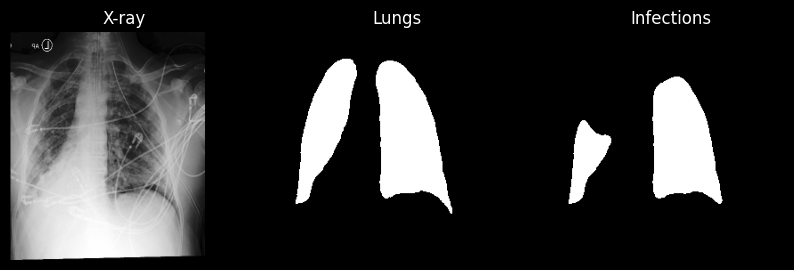

In [5]:
dataset = train_loader.dataset

image, label, seg_targets = dataset[8912]
print(f"Class Label: ", LABEL_NAMES[label])

img_np = image.squeeze(0).numpy()  # [H, W]
lng_np = seg_targets[1].numpy()    # Lungs channel
inf_np = seg_targets[2].numpy()    # Infection channel

# Plot
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_np, cmap='gray')
plt.title("X-ray")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(lng_np, cmap='gray')
plt.title("Lungs")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(inf_np, cmap='gray')
plt.title("Infections")
plt.axis('off')

plt.show()

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from torchvision import models


class CNNXRayNet(nn.Module):
    def __init__(self, n_classes_cls=3, n_classes_seg=3, dropout=0.3):
        super().__init__()

        # --- Shared CNN backbone ---
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        # --- Project global feature to spatial map for UNet ---
        self.global_to_map = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, 1),
            nn.ReLU(inplace=True),
        )

        # --- UNet for segmentation ---
        self.unet = smp.Unet(
            encoder_name="resnet34",      # lightweight encoder for speed
            encoder_weights=None,
            in_channels=64 + 1,           # backbone + global map
            classes=n_classes_seg,
        )

        # --- Classification head: global pooled features ---
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, n_classes_cls),
        )

    def forward(self, x):
        B, _, H, W = x.shape

        # Shared backbone
        feat = self.backbone(x)  # (B, 64, H, W)

        # Classification: global pooled
        cls_logits = self.classifier(feat)

        # Segmentation: inject global feature map
        global_map = self.global_to_map(feat).view(B, 1, 1, 1).expand(-1, 1, H, W)
        seg_input = torch.cat([feat, global_map], dim=1)
        seg_logits = self.unet(seg_input)

        return cls_logits, seg_logits

In [7]:
import torch
from torch import nn
import segmentation_models_pytorch as smp
from torchmetrics.classification import MultilabelF1Score, MultilabelJaccardIndex

def compute_loss(cls_logits, seg_logits, cls_labels, seg_targets):
    # --- Classification Loss ---
    cls_loss_fn = nn.CrossEntropyLoss(weight=weights)
    cls_loss = cls_loss_fn(cls_logits, cls_labels)

    # --- Segmentation Loss ---
    dice_loss_fn = smp.losses.DiceLoss(mode='multilabel')  
    bce_loss_fn = smp.losses.SoftBCEWithLogitsLoss()

    dice_loss = dice_loss_fn(seg_logits, seg_targets)
    bce_loss = bce_loss_fn(seg_logits, seg_targets)

    seg_loss = dice_loss + bce_loss
    total_loss = cls_loss + seg_loss

    return total_loss, cls_loss, seg_loss

def compute_metrics(seg_logits, seg_targets):
    num_labels = seg_logits.size(1)
    device = seg_logits.device
    probs = torch.sigmoid(seg_logits)

    f1 = MultilabelF1Score(num_labels=num_labels, average="micro").to(device)
    iou = MultilabelJaccardIndex(num_labels=num_labels, average="micro").to(device)

    dice = f1(probs, seg_targets.int())
    iou = iou(probs, seg_targets.int())

    return dice.item(), iou.item()

In [8]:
import copy
from tqdm.notebook import tqdm

def display_metrics(metrics):
    print(f"Training Metrics:")
    print(f"Epoch Loss:          {metrics['train_epoch_loss'][-1]:.4f}")
    print(f"Batch Loss:          {metrics['train_loss'][-1]:.4f}")
    print(f"Classification Loss: {metrics['train_cls_loss'][-1]:.4f}")
    print(f"Segmentation Loss:   {metrics['train_seg_loss'][-1]:.4f}")
    print(f"Dice Score:          {metrics['train_dice'][-1]:.2f}")
    print(f"IoU Score:           {metrics['train_iou'][-1]:.2f}")

    print(f"\n")
    print(f"Validation Metrics:")
    print(f"Epoch Loss:          {metrics['val_epoch_loss'][-1]:.4f}")
    print(f"Batch Loss:          {metrics['val_loss'][-1]:.4f}")
    print(f"Classification Loss: {metrics['val_cls_loss'][-1]:.4f}")
    print(f"Segmentation Loss:   {metrics['val_seg_loss'][-1]:.4f}")
    print(f"Dice Score:          {metrics['val_dice'][-1]:.2f}")
    print(f"IoU Score:           {metrics['val_iou'][-1]:.2f}")

def train(
    epochs, model,
    train_loader, val_loader,
    optimizer, scheduler, compute_loss,
    clip_val, metrics, device,
    save_path="best_model.pth"
):
    best_val_loss = float('inf')
    best_model = None

    for epoch in range(epochs):
        model.train()
        total = 0
        loop = tqdm(train_loader, desc=f"Training [{epoch+1}/{epochs}]", leave=False)

        for images, cls_labels, seg_targets in loop:
            images = images.to(device)
            cls_labels = cls_labels.to(device)
            seg_targets = seg_targets.to(device)

            optimizer.zero_grad()
            cls_logits, seg_logits = model(images)
            loss, cls_loss, seg_loss = compute_loss(cls_logits, seg_logits, cls_labels, seg_targets)
            dice, iou = compute_metrics(seg_logits, seg_targets)

            key_value = {
                "train_loss"    : loss,
                "train_cls_loss": cls_loss,
                "train_seg_loss": seg_loss,
                "train_dice"    : dice,
                "train_iou"     : iou
            }

            total += loss.item()
            for key, value in key_value.items():
                metrics.setdefault(key, []).append(value)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip_val)
            optimizer.step()
            scheduler.step()

            loop.set_postfix(loss=loss.item())

        # Train Epoch Loss
        value = total/len(train_loader)
        metrics.setdefault("train_epoch_loss", []).append(value)
        
        # Validation
        val_loss = validate(model, val_loader, compute_loss, metrics, device)

        # Save best model by validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model = copy.deepcopy(model)

        # Display the metrics
        print(f"\n---------------- Epoch: [{epoch+1}/{epochs}] ----------------")
        display_metrics(metrics)

    # Save the best model
    torch.save(best_model, "model.pth")

def validate(model, loader, compute_loss, metrics, device):
    model.eval()

    with torch.no_grad():
        total = 0
        loop = tqdm(loader, desc='Validating', leave=False)
        for images, cls_labels, seg_targets in loop:
            images = images.to(device)
            cls_labels = cls_labels.to(device)
            seg_targets = seg_targets.to(device)

            cls_logits, seg_logits = model(images)
            loss, cls_loss, seg_loss = compute_loss(cls_logits, seg_logits, cls_labels, seg_targets)
            dice, iou = compute_metrics(seg_logits, seg_targets)
            
            key_value = {
                "val_loss"    : loss,
                "val_cls_loss": cls_loss,
                "val_seg_loss": seg_loss,
                "val_dice"    : dice,
                "val_iou"     : iou
            }

            total += loss.item()
            for key, value in key_value.items():
                metrics.setdefault(key, []).append(value)

            loop.set_postfix(loss=loss.item())

        # Validation Epoch Loss
        value = total/len(loader)
        metrics.setdefault("val_epoch_loss", []).append(value)

    return value

def plot_metrics(metrics):
    for key, values in metrics.items():
        processed = [
            v.detach().cpu().item() if isinstance(v, torch.Tensor) else v
            for v in values
        ]
        
        plt.figure()
        plt.plot(processed)
        plt.title(key)
        plt.xlabel("Step")
        plt.ylabel(key)
        plt.grid(True)
        plt.show()

Training [1/50]:   0%|          | 0/924 [00:00<?, ?it/s]

Validating:   0%|          | 0/231 [00:00<?, ?it/s]


---------------- Epoch: [1/50] ----------------
Training Metrics:
Epoch Loss:          1.7849
Batch Loss:          1.2498
Classification Loss: 0.8950
Segmentation Loss:   0.3547
Dice Score:          0.94
IoU Score:           0.88


Validation Metrics:
Epoch Loss:          1.2059
Batch Loss:          1.1657
Classification Loss: 0.8430
Segmentation Loss:   0.3227
Dice Score:          0.95
IoU Score:           0.90


Training [2/50]:   0%|          | 0/924 [00:00<?, ?it/s]

Validating:   0%|          | 0/231 [00:00<?, ?it/s]

...

Validating:   0%|          | 0/231 [00:00<?, ?it/s]


---------------- Epoch: [49/50] ----------------
Training Metrics:
Epoch Loss:          0.6416
Batch Loss:          0.6621
Classification Loss: 0.6191
Segmentation Loss:   0.0431
Dice Score:          0.99
IoU Score:           0.98


Validation Metrics:
Epoch Loss:          0.5629
Batch Loss:          0.6845
Classification Loss: 0.6094
Segmentation Loss:   0.0751
Dice Score:          0.98
IoU Score:           0.96


Training [50/50]:   0%|          | 0/924 [00:00<?, ?it/s]

Validating:   0%|          | 0/231 [00:00<?, ?it/s]


---------------- Epoch: [50/50] ----------------
Training Metrics:
Epoch Loss:          0.6364
Batch Loss:          0.6856
Classification Loss: 0.6320
Segmentation Loss:   0.0536
Dice Score:          0.99
IoU Score:           0.98


Validation Metrics:
Epoch Loss:          0.5538
Batch Loss:          0.6589
Classification Loss: 0.5843
Segmentation Loss:   0.0746
Dice Score:          0.98
IoU Score:           0.96


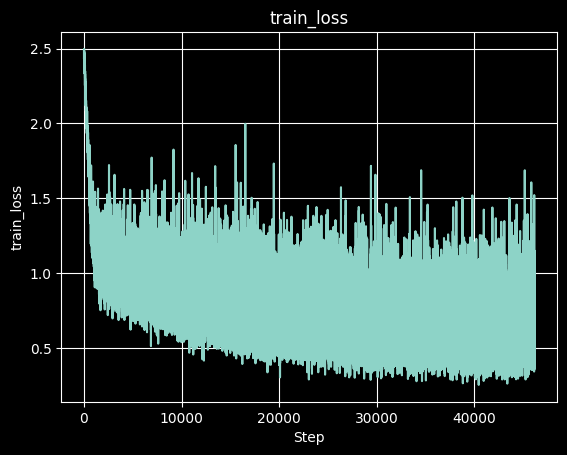

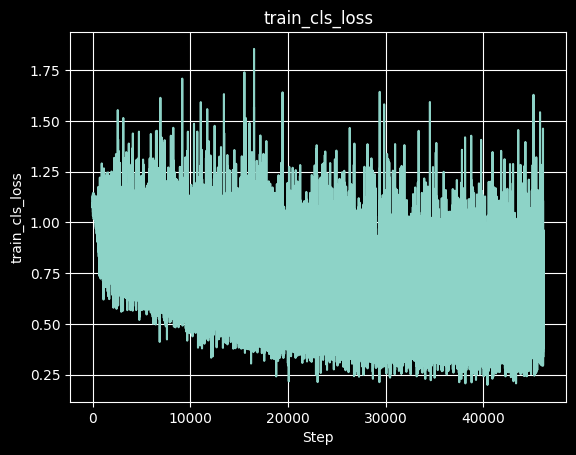

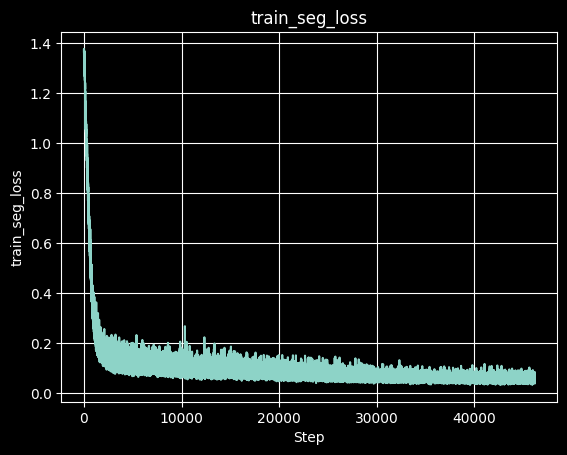

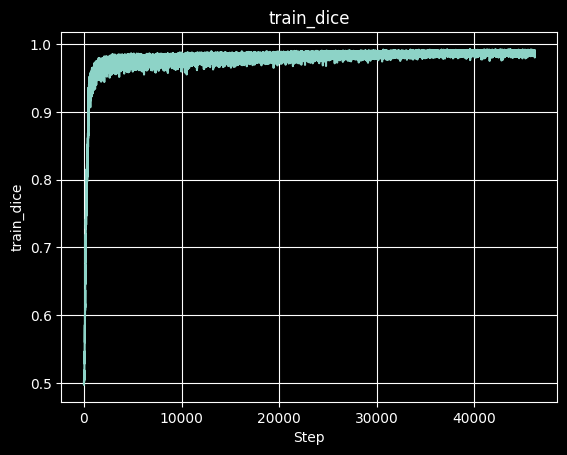

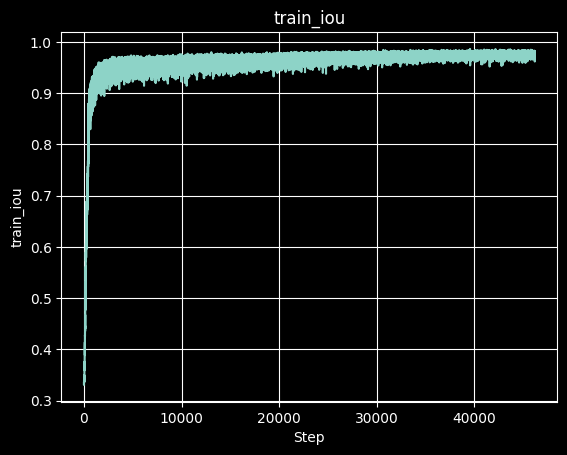

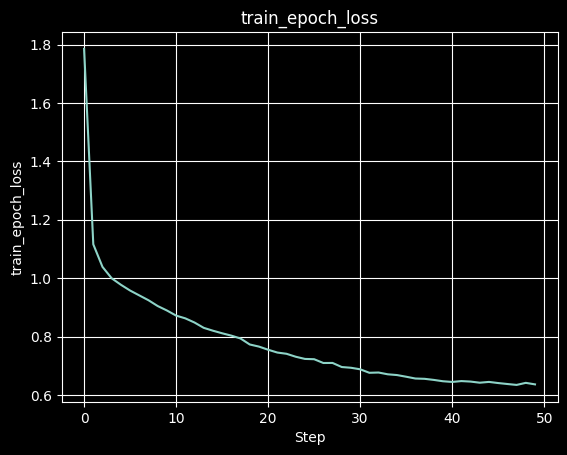

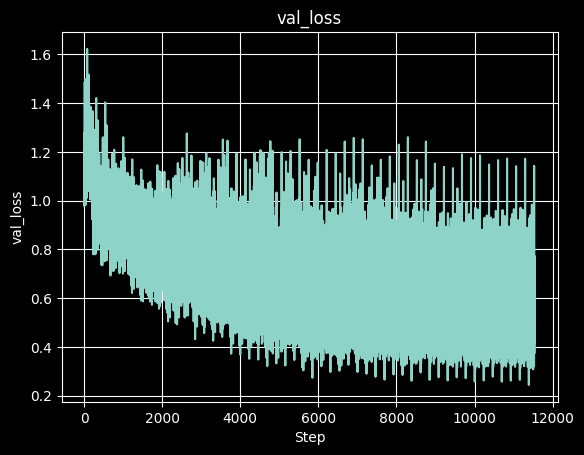

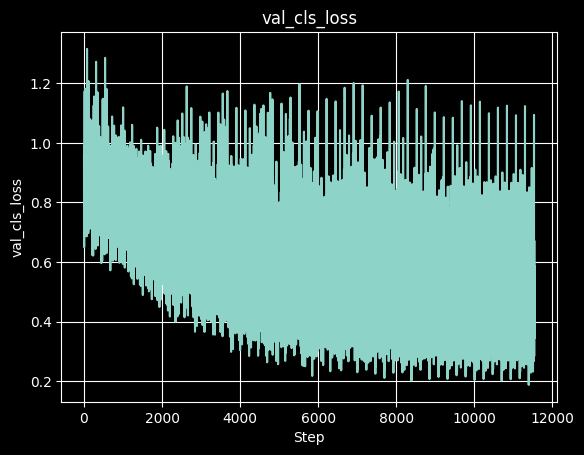

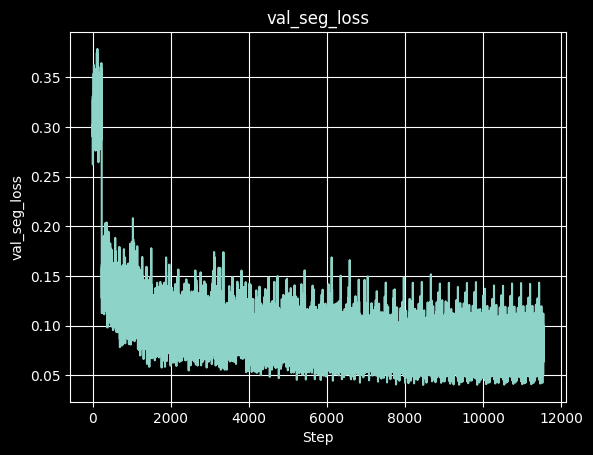

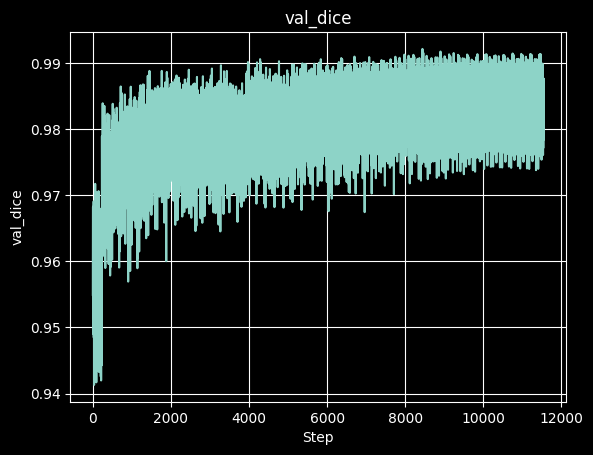

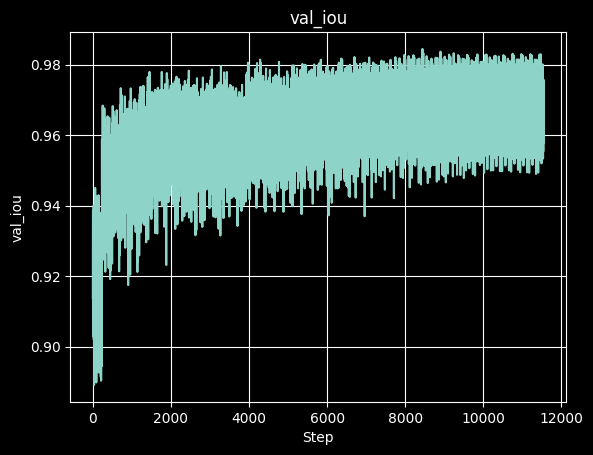

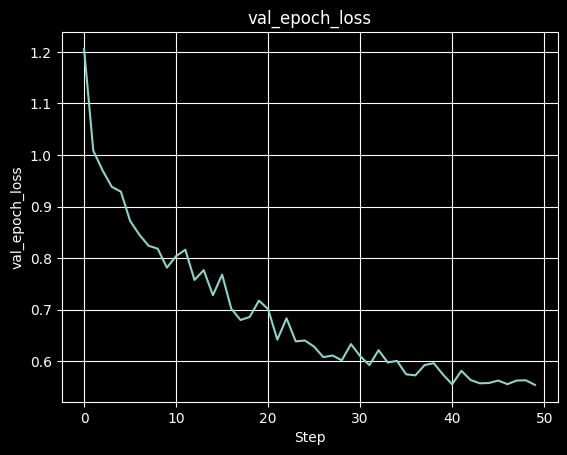

In [9]:
import torch.optim as optim
from transformers import get_cosine_schedule_with_warmup

model = CNNXRayNet(n_classes_cls=3, n_classes_seg=3).to(device)
epochs = 50
lr = 1e-4
clip_val = 1.0

optimizer = optim.AdamW(model.parameters(), lr=lr)
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=len(train_loader),
    num_training_steps=epochs*len(train_loader)
)

metrics = {}

train(
    epochs, model,
    train_loader, val_loader,
    optimizer, scheduler, compute_loss,
    clip_val, metrics, device,
)
plot_metrics(metrics)

In [10]:
def load_model(path='model.pth'):
    model = torch.load(path, weights_only=False)
    model.eval()

    return model

@torch.no_grad()
def visualize(model, loader, device, N=None):
    images, cls_labels, seg_targets = next(iter(loader))
    images = images.to(device)

    if N:
        images = images[:N]
        cls_labels = cls_labels[:N]
        seg_targets = seg_targets[:N]

    cls_logits, seg_logits = model(images)
    pred_cls = cls_logits.argmax(dim=1)
    pred_seg = torch.sigmoid(seg_logits)

    B = images.size(0)
    plt.figure(figsize=(16, B * 4))

    for i in range(B):
        actual_cls = LABEL_NAMES[cls_labels[i].item()]
        predicted_cls = LABEL_NAMES[pred_cls[i].item()]

        image = images[i].permute(1, 2, 0).cpu().numpy()
        
        lungs_gt = seg_targets[i, 1, :, :].cpu().numpy()
        lesions_gt = seg_targets[i, 2, :, :].cpu().numpy()

        lungs_pred = pred_seg[i, 1, :, :].cpu().numpy()
        lesions_pred = pred_seg[i, 2, :, :].cpu().numpy()

        # Original Image
        plt.subplot(B, 3, i*3 + 1)
        plt.imshow(image)
        plt.axis("off")
        plt.title(f"GT {actual_cls} | Pred {predicted_cls}")
        
        # Ground Truth Masks
        plt.subplot(B, 3, i*3 + 2)
        plt.imshow(image, alpha=1.0)
        plt.imshow(lungs_gt, cmap="Blues", alpha=0.5)
        plt.imshow(lesions_gt, cmap="Reds", alpha=0.4)
        plt.axis("off")
        plt.title("Ground Truth Masks")
        
        # Predicted Masks
        plt.subplot(B, 3, i*3 + 3)
        plt.imshow(image, alpha=1.0)
        plt.imshow(lungs_pred, cmap="Blues", alpha=0.5)
        plt.imshow(lesions_pred, cmap="Reds", alpha=0.4)
        plt.axis("off")
        plt.title("Predicted Masks (heatmap)")

    plt.tight_layout()
    plt.show()

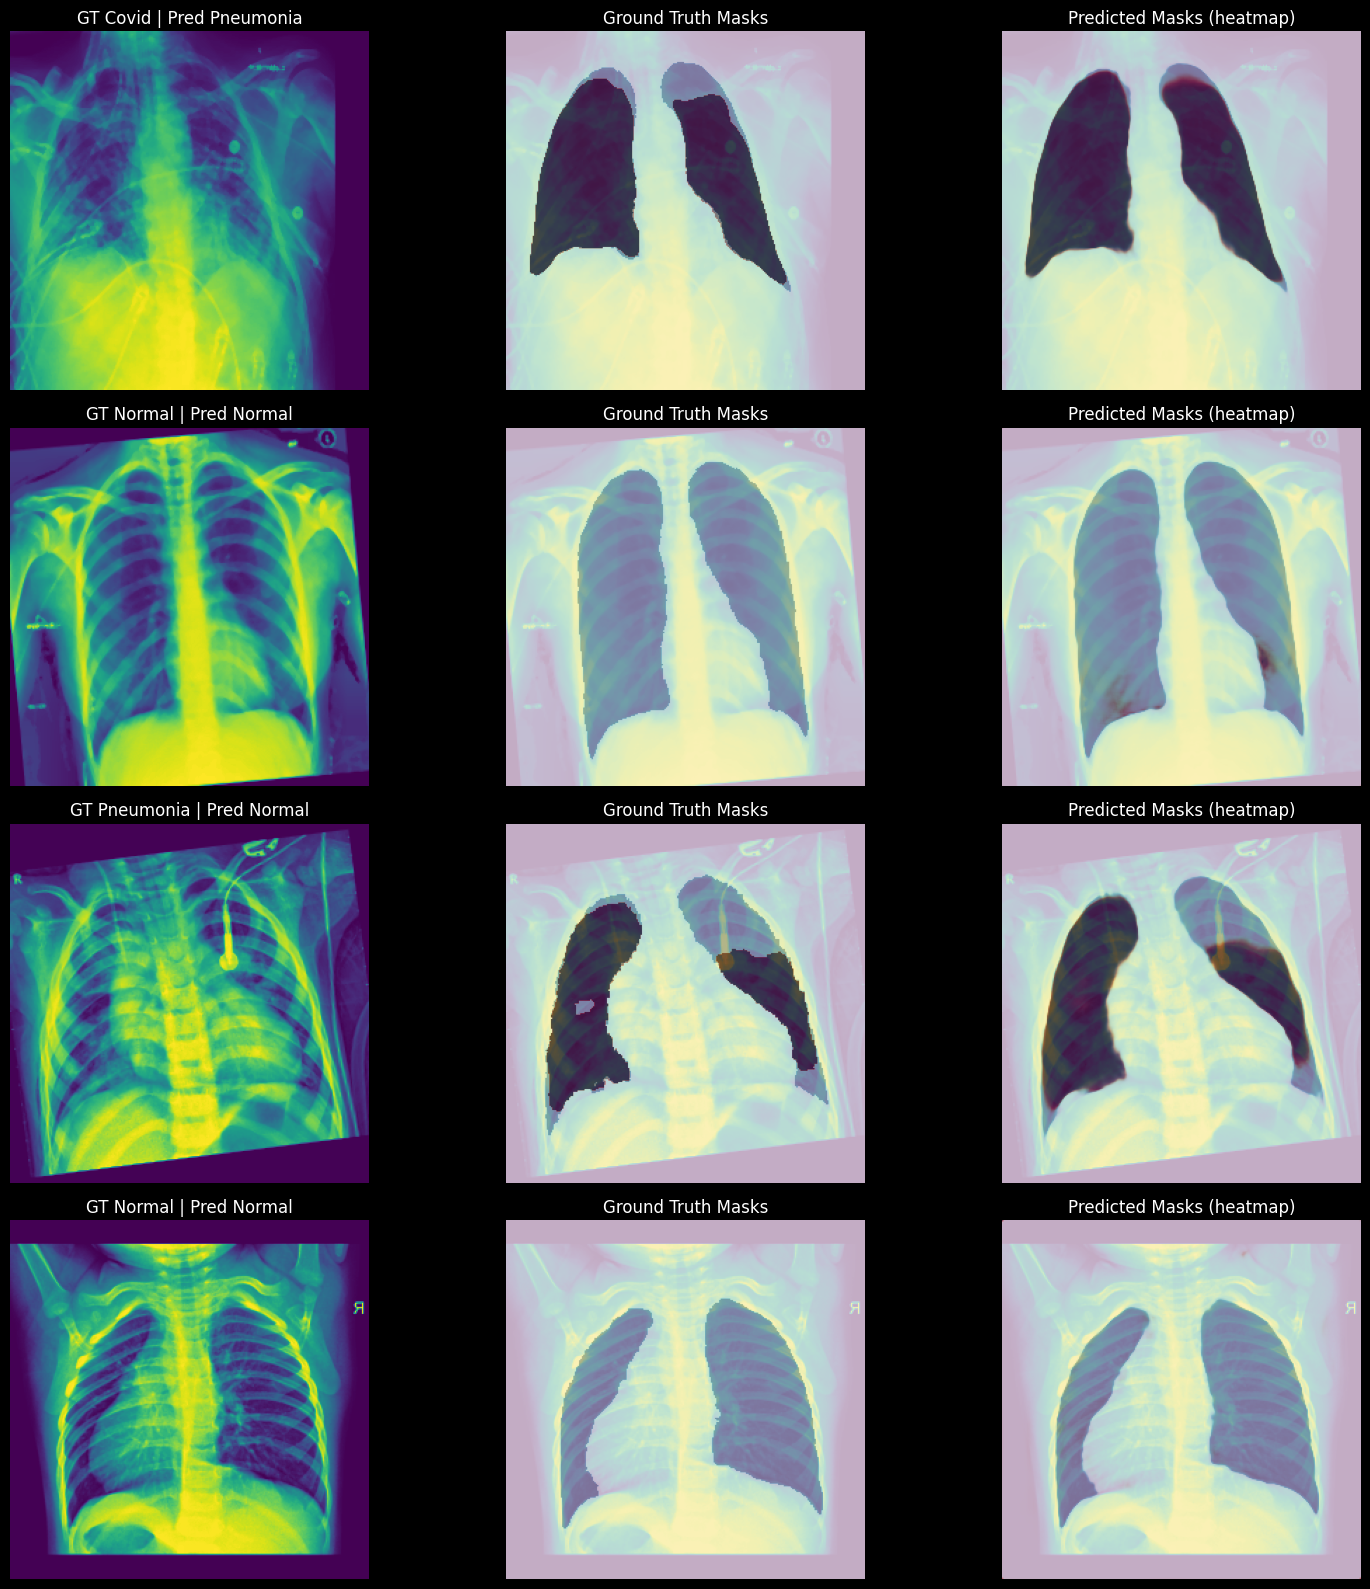

In [11]:
model = load_model("model.pth")
visualize(model, train_loader, device, N=4)

In [12]:
from sklearn.metrics import classification_report, confusion_matrix

def evaluate(model, dataloader, class_names, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels, _ in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            cls_logits, _ = model(images)
            preds = cls_logits.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # ---------------------- Classification Report ---------------------- #
    print("📊 Classification Report:")
    report = classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        digits=4
    )
    print(report)

    # ---------------------- Confusion Matrix ---------------------- #
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names if class_names else "Pred",
        yticklabels=class_names if class_names else "True"
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

📊 Classification Report:
              precision    recall  f1-score   support

      Normal     0.7180    0.7475    0.7325       705
       Covid     0.9494    0.9067    0.9276      1822
   Pneumonia     0.7676    0.8024    0.7846      1169

    accuracy                         0.8433      3696
   macro avg     0.8117    0.8189    0.8149      3696
weighted avg     0.8478    0.8433    0.8451      3696



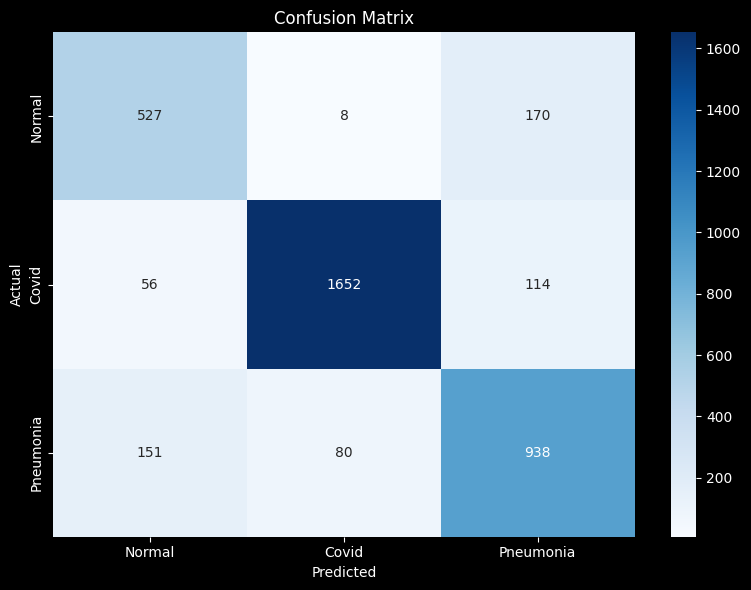

In [13]:
evaluate(
    model=model,
    dataloader=val_loader,
    class_names=["Normal", "Covid", "Pneumonia"],
    device=device,
)

In [14]:
# Inference

#model_path = "/kaggle/input/cnn-vit-u-net/pytorch/v1/1/best_model.pth"
#model = load_model(model_path)

In [15]:
"""@torch.no_grad()
def process_image(image: Image.Image):
    threshold = 0.75
    # Transform image
    input_tensor = transform(image).unsqueeze(0).to(device)
    original = np.array(image.resize((224, 224))).astype(np.float32) / 255.0

    # Forward pass
    cls_logits, seg_logits = model(input_tensor)
    pred_label = cls_logits.argmax(dim=1).item()
    pred_label = LABEL_NAMES[pred_label]

    # Segmentation outputs
    seg_probs = torch.sigmoid(seg_logits[0]).cpu().numpy()
    lung_pred = seg_probs[0]
    infect_pred = seg_probs[1]

    # Thresholded masks
    lung_mask = lung_pred > threshold
    infect_mask = infect_pred > threshold

    # Severity calculation
    lung_area = lung_mask.sum()
    infected_area = (infect_mask & lung_mask).sum()
    severity = (infected_area / (lung_area + 1e-8)) * 100

    # Overlays
    lung_overlay = overlay_mask_on_image(original, lung_mask, color=(0.4, 0.8, 1.0))  # blue
    infect_overlay = overlay_mask_on_image(original, infect_mask, color=(1.0, 0.0, 0.0))  # red

    # Convert to uint8 image for Gradio compatibility
    lung_overlay = (lung_overlay * 255).astype(np.uint8)
    infect_overlay = (infect_overlay * 255).astype(np.uint8)

    string = f"Predicted: {pred_label} | Severity:  {severity:.2f}"

    return string, lung_overlay, infect_overlay"""

'@torch.no_grad()\ndef process_image(image: Image.Image):\n    threshold = 0.75\n    # Transform image\n    input_tensor = transform(image).unsqueeze(0).to(device)\n    original = np.array(image.resize((224, 224))).astype(np.float32) / 255.0\n\n    # Forward pass\n    cls_logits, seg_logits = model(input_tensor)\n    pred_label = cls_logits.argmax(dim=1).item()\n    pred_label = LABEL_NAMES[pred_label]\n\n    # Segmentation outputs\n    seg_probs = torch.sigmoid(seg_logits[0]).cpu().numpy()\n    lung_pred = seg_probs[0]\n    infect_pred = seg_probs[1]\n\n    # Thresholded masks\n    lung_mask = lung_pred > threshold\n    infect_mask = infect_pred > threshold\n\n    # Severity calculation\n    lung_area = lung_mask.sum()\n    infected_area = (infect_mask & lung_mask).sum()\n    severity = (infected_area / (lung_area + 1e-8)) * 100\n\n    # Overlays\n    lung_overlay = overlay_mask_on_image(original, lung_mask, color=(0.4, 0.8, 1.0))  # blue\n    infect_overlay = overlay_mask_on_image(or

In [16]:
"""import gradio as gr

demo = gr.Interface(
    fn=process_image,
    inputs=[
        gr.Image(type="pil", label="CXR Image"),
    ],
    outputs=[
        gr.Label(label="Predictions"),
        gr.Image(label="Lung Mask"),
        gr.Image(label="Infection Mask"),
    ],
    title="CXR Disease and Severity Classifier",
    description="Upload a chest X-ray to classify disease, segment lungs/infection, and score severity.",
)

demo.launch(share=True)"""

'import gradio as gr\n\ndemo = gr.Interface(\n    fn=process_image,\n    inputs=[\n        gr.Image(type="pil", label="CXR Image"),\n    ],\n    outputs=[\n        gr.Label(label="Predictions"),\n        gr.Image(label="Lung Mask"),\n        gr.Image(label="Infection Mask"),\n    ],\n    title="CXR Disease and Severity Classifier",\n    description="Upload a chest X-ray to classify disease, segment lungs/infection, and score severity.",\n)\n\ndemo.launch(share=True)'